In [8]:
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from IPython.display import display
SEEDS = [0, 1, 2]
N_TREES = 200
MAX_SAMPLES = 'auto'
MAX_ALARM_FRACTION = 0.01
MAX_EPISODES_PER_WEEK = 1.0
MERGE_GAP_HOURS = 0
HOURS_PER_WEEK = 168
required_files = ['train_scaled.csv', 'val_scaled.csv', 'cal_scaled.csv', 'dataset2_eval.csv']
candidates = [Path('/content/files'), Path('/content'), Path.cwd() / 'files', Path.cwd(), Path('data/processed'), Path('../../data/processed')]
DATA_DIR = next((p.resolve() for p in candidates if all((p / filename).is_file() for filename in required_files)), None)
if DATA_DIR is None:
    locations = ', '.join(str(p) for p in candidates)
    raise FileNotFoundError(f'Upload all four CSV files into /content/files/ (or /content/). Searched: {locations}')
OUTPUT_DIR = Path('/content/iforest_results') if Path('/content').exists() else Path('iforest_results')


In [9]:
assert DATA_DIR is not None, 'Set DATA_DIR to the folder containing the four required CSV files.'
DATA_DIR = Path(DATA_DIR)
files_required = {'train':'train_scaled.csv','val':'val_scaled.csv','cal':'cal_scaled.csv','dev':'dataset2_eval.csv'}
for fn in files_required.values():
    assert (DATA_DIR/fn).exists(), f'Missing {DATA_DIR/fn}'
tables = {part:pd.read_csv(DATA_DIR/name, parse_dates=['DATETIME']) for part,name in files_required.items()}
SPECIAL = {'DATETIME','ATT_FLAG','label','attack_id'}
feature_names = [c for c in tables['train'].columns if c not in SPECIAL]
assert len(feature_names)==36, f'Expected 36 features, got {len(feature_names)}'
assert sum(c.startswith('S_') for c in feature_names)==8
assert sum(not c.startswith('S_') for c in feature_names)==28
for name, df in tables.items():
    assert [c for c in df.columns if c not in SPECIAL] == feature_names, f'{name}: feature columns/order differ'
    assert not df['DATETIME'].isna().any(), f'{name}: invalid DATETIME'
    assert df['DATETIME'].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all(), f'{name}: non-hourly timestamps'
    assert np.isfinite(df[feature_names].to_numpy(dtype=float)).all(), f'{name}: non-finite values'
    assert all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_names), f'{name}: non-numeric feature'
    if name != 'dev':
        assert df['ATT_FLAG'].eq(0).all(), f'{name}: this split must be completely normal'
for first, second in [('train','val'),('val','cal')]:
    gap = (tables[second].DATETIME.iloc[0]-tables[first].DATETIME.iloc[-1])/pd.Timedelta(hours=1)-1
    assert gap >= 24, f'{first}/{second}: missing 24-hour gap'
assert len(tables['train']) == 5256 and len(tables['val']) == 1728 and len(tables['cal']) == 1729
assert len(tables['dev']) == 4177, 'Dataset 2 should contain 4,177 hours'
assert {'label','attack_id'}.issubset(tables['dev'].columns), 'dataset2_eval.csv must contain label and attack_id'
assert tables['dev']['label'].isin([0,1]).all(), 'Evaluation label must be 0/1'
assert tables['dev']['attack_id'].notna().all()
assert tables['dev']['label'].sum() == 492, 'Expected 492 published attack hours'
assert set(tables['dev']['attack_id'].unique()) == set(range(8)), 'Expected attack ids 0..7'
assert (tables['dev']['label'].eq(1) == tables['dev']['attack_id'].ne(0)).all()
display(pd.DataFrame([{'split':k,'rows':len(v),'features':len(feature_names),'start':v.DATETIME.iloc[0], 'end':v.DATETIME.iloc[-1]} for k,v in tables.items()]))
print('Attack hours:',int(tables['dev'].label.sum()), '| Outside known attacks:',int((tables['dev'].label==0).sum()))
print('Input features:',feature_names)

,split,rows,features,start,end
0,train,5256,36,2014-01-06,2014-08-12 23:00:00
1,val,1728,36,2014-08-14,2014-10-24 23:00:00
2,cal,1729,36,2014-10-26,2015-01-06 00:00:00
3,dev,4177,36,2016-07-04,2016-12-25 00:00:00


Attack hours: 492 | Outside known attacks: 3685
Input features: ['L_T1', 'L_T2', 'L_T3', 'L_T4', 'L_T5', 'L_T6', 'L_T7', 'F_PU1', 'F_PU2', 'S_PU2', 'F_PU4', 'S_PU4', 'F_PU6', 'S_PU6', 'F_PU7', 'S_PU7', 'F_PU8', 'S_PU8', 'F_PU10', 'S_PU10', 'F_PU11', 'S_PU11', 'F_V2', 'S_V2', 'P_J280', 'P_J269', 'P_J300', 'P_J256', 'P_J289', 'P_J415', 'P_J302', 'P_J306', 'P_J307', 'P_J317', 'P_J14', 'P_J422']


In [10]:
HOURS_WEEK = 168
def episode_spans(alarms, merge_gap_hours=0):
    idx = np.flatnonzero(alarms)
    if len(idx) == 0:
        return []
    cuts = np.flatnonzero(np.diff(idx) > merge_gap_hours + 1)
    starts = np.r_[idx[0], idx[cuts + 1]]
    ends = np.r_[idx[cuts], idx[-1]]
    return [(int(a), int(b)) for a, b in zip(starts, ends)]
def clean_stats(scores, threshold, merge_gap_hours=0):
    alarm = scores > threshold
    episodes = len(episode_spans(alarm, merge_gap_hours))
    return {'hours': len(scores), 'alarm_hours': int(alarm.sum()),
            'alarm_fraction': float(alarm.mean()), 'episodes': episodes,
            'episodes_per_week': float(episodes * HOURS_WEEK / len(scores))}
def find_threshold(scores, max_alarm_fraction=0.01, max_episodes_per_week=1.0, merge_gap_hours=0):
    best = float(np.max(scores))
    for threshold in np.unique(scores)[::-1]:
        s = clean_stats(scores, float(threshold), merge_gap_hours)
        if (s['alarm_fraction'] <= max_alarm_fraction + 1e-12
                and s['episodes_per_week'] <= max_episodes_per_week + 1e-12):
            best = float(threshold)
    return best
def evaluate(scores, threshold, labels, attack_id, attacks, merge_gap_hours=0):
    alarm = scores > threshold
    tp = int((alarm & (labels == 1)).sum())
    fp = int((alarm & (labels == 0)).sum())
    fn = int((~alarm & (labels == 1)).sum())
    tn = int((~alarm & (labels == 0)).sum())
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    per_attack, delays = [], []
    for attack in attacks:
        in_attack = np.flatnonzero((attack_id == attack['id']) & alarm)
        delay = None if not len(in_attack) else int(in_attack[0] - np.flatnonzero(attack_id == attack['id'])[0])
        per_attack.append({**attack, 'detected': delay is not None, 'delay_hours': delay})
        if delay is not None:
            delays.append(delay)
    clean_alarm = alarm & (labels == 0)
    false_episodes = len(episode_spans(clean_alarm, merge_gap_hours))
    tnr = tn / (tn + fp)
    metrics = {
        'model': 'isolation_forest_static', 'label_rule': 'published_attack_windows_assumed_normal_outside',
        'threshold': threshold, 'attacks_detected': sum(x['detected'] for x in per_attack),
        'attacks_total': len(attacks),
        'missed_attacks': ','.join(str(x['id']) for x in per_attack if not x['detected']),
        'mean_delay_hours': float(np.mean(delays)) if delays else None,
        'median_delay_hours': float(np.median(delays)) if delays else None,
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'precision': precision, 'recall': recall, 'f1': f1,
        'roc_auc': float(roc_auc_score(labels, scores)),
        'pr_auc': float(average_precision_score(labels, scores)),
        'false_alarm_episodes': false_episodes,
        'false_alarm_episodes_per_week': float(false_episodes * HOURS_WEEK / (tn + fp)),
        'clean_hours_under_alarm': fp / (tn + fp),
        'true_negative_rate': tnr,
    }
    return metrics, per_attack, alarm
def write_plot(when, scores, threshold, labels, output):
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(when, scores, lw=0.8, label='Isolation Forest anomaly score')
    ax.axhline(threshold, ls='--', c='black', lw=1, label='calibrated threshold')
    for i, (a, b) in enumerate(episode_spans(labels == 1)):
        ax.axvspan(when.iloc[a], when.iloc[b], color='orange', alpha=0.18,
                   label='published attack window' if i == 0 else None)
    ax.set(xlabel='Hour', ylabel='Anomaly score (larger = more anomalous)',
           title='BATADAL Dataset 2 | static Isolation Forest')
    ax.legend(loc='upper right')
    fig.tight_layout()
    fig.savefig(output, dpi=160)
    plt.close(fig)


In [11]:
dev = tables['dev']
labels = dev['label'].to_numpy(dtype=int)
attack_ids = dev['attack_id'].to_numpy(dtype=int)
attacks = []
for attack_id in range(1,8):
    idx=np.flatnonzero(attack_ids==attack_id)
    assert len(idx)>0 and np.all(np.diff(idx)==1), f'Attack {attack_id} is missing/not contiguous'
    attacks.append({'id':attack_id,'start':str(dev.DATETIME.iloc[idx[0]]),
                    'end':str(dev.DATETIME.iloc[idx[-1]]),'hours':len(idx)})
assert [a['hours'] for a in attacks]==[50,24,60,94,60,94,110]
display(pd.DataFrame(attacks))


,id,start,end,hours
0,1,2016-09-13 23:00:00,2016-09-16 00:00:00,50
1,2,2016-09-26 11:00:00,2016-09-27 10:00:00,24
2,3,2016-10-09 09:00:00,2016-10-11 20:00:00,60
3,4,2016-10-29 19:00:00,2016-11-02 16:00:00,94
4,5,2016-11-26 17:00:00,2016-11-29 04:00:00,60
5,6,2016-12-06 07:00:00,2016-12-10 04:00:00,94
6,7,2016-12-14 15:00:00,2016-12-19 04:00:00,110


In [12]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
all_metrics=[]
per_attack_results=[]
calibration_results=[]
for seed in SEEDS:
    out=OUTPUT_DIR/f'seed{seed}'
    out.mkdir(parents=True,exist_ok=True)
    forest=IsolationForest(n_estimators=N_TREES,max_samples=MAX_SAMPLES,
                           contamination='auto',random_state=seed,n_jobs=-1)
    forest.fit(tables['train'][feature_names].to_numpy())
    scores={k:-forest.score_samples(df[feature_names].to_numpy()) for k,df in tables.items()}
    threshold=find_threshold(scores['cal'],MAX_ALARM_FRACTION,MAX_EPISODES_PER_WEEK,MERGE_GAP_HOURS)
    cal_stats=clean_stats(scores['cal'],threshold,MERGE_GAP_HOURS)
    val_stats=clean_stats(scores['val'],threshold,MERGE_GAP_HOURS)
    cal_ok=(cal_stats['alarm_fraction']<=MAX_ALARM_FRACTION+1e-12 and
            cal_stats['episodes_per_week']<=MAX_EPISODES_PER_WEEK+1e-12)
    val_ok=(val_stats['alarm_fraction']<=MAX_ALARM_FRACTION+1e-12 and
            val_stats['episodes_per_week']<=MAX_EPISODES_PER_WEEK+1e-12)
    assert cal_ok, 'Threshold must satisfy calibration constraints'
    metrics,per_attack,alarm=evaluate(scores['dev'],threshold,labels,attack_ids,attacks,MERGE_GAP_HOURS)
    metrics.update(seed=seed,n_estimators=N_TREES,calib_in_budget=cal_ok,val_in_budget=val_ok)
    calibration={'threshold':threshold,'scoring':'-IsolationForest.score_samples(X)',
                 'operator':'score > threshold','seed':seed,'n_estimators':N_TREES,
                 'max_samples':MAX_SAMPLES,'max_alarm_fraction':MAX_ALARM_FRACTION,
                 'max_episodes_per_week':MAX_EPISODES_PER_WEEK,'merge_gap_hours':MERGE_GAP_HOURS,
                 'calib_stats':cal_stats,'val_stats':val_stats,'val_in_budget':val_ok,
                 'feature_names':feature_names}
    joblib.dump({'model':forest,'feature_names':feature_names,'threshold':threshold},out/'model.joblib')
    (out/'calibration.json').write_text(json.dumps(calibration,indent=2))
    (out/'metrics.json').write_text(json.dumps(metrics,indent=2))
    pd.DataFrame(per_attack).to_csv(out/'per_attack.csv',index=False)
    pd.DataFrame({'DATETIME':dev.DATETIME,'score':scores['dev'],'threshold':threshold,
                  'alarm':alarm.astype(int),'attack_id':attack_ids,'label':labels,
                  'original_ATT_FLAG':dev.ATT_FLAG}).to_csv(out/'hourly_scores.csv',index=False)
    write_plot(dev.DATETIME,scores['dev'],threshold,labels,out/'timeline.png')
    all_metrics.append(metrics)
    per_attack_results.extend([{'seed':seed,**record} for record in per_attack])
    calibration_results.append({'seed':seed,'threshold':threshold,'calibration_episodes_per_week':cal_stats['episodes_per_week'],
                                'calibration_alarm_fraction':cal_stats['alarm_fraction'],
                                'validation_episodes_per_week':val_stats['episodes_per_week'],
                                'validation_alarm_fraction':val_stats['alarm_fraction'],
                                'validation_in_budget':val_ok})
    print(f'Seed {seed} | attack detection {metrics["attacks_detected"]}/7 | '
          f'precision {metrics["precision"]:.4f} | recall {metrics["recall"]:.4f} | '
          f'F1 {metrics["f1"]:.4f} | validation budget {val_ok}')
summary=pd.DataFrame(all_metrics)
summary.to_csv(OUTPUT_DIR/'seed_comparison.csv',index=False)
pd.DataFrame(per_attack_results).to_csv(OUTPUT_DIR/'all_per_attack.csv',index=False)
pd.DataFrame(calibration_results).to_csv(OUTPUT_DIR/'all_calibration.csv',index=False)
print('Saved outputs to',OUTPUT_DIR.resolve())


Seed 0 | attack detection 5/7 | precision 0.3182 | recall 0.0285 | F1 0.0522 | validation budget False
Seed 1 | attack detection 6/7 | precision 0.2456 | recall 0.0285 | F1 0.0510 | validation budget False
Seed 2 | attack detection 5/7 | precision 0.2889 | recall 0.0264 | F1 0.0484 | validation budget True
Saved outputs to /content/iforest_results


,seed,attacks_detected,tp,fp,fn,tn,precision,recall,f1,roc_auc,pr_auc,mean_delay_hours,false_alarm_episodes_per_week,clean_hours_under_alarm,calib_in_budget,val_in_budget
0,0,5,14,30,478,3655,0.3182,0.0285,0.0522,0.6443,0.2119,33.4000,1.2765,0.0081,True,False
1,1,6,14,43,478,3642,0.2456,0.0285,0.0510,0.6455,0.2018,37.6667,1.6868,0.0117,True,False
2,2,5,13,32,479,3653,0.2889,0.0264,0.0484,0.6402,0.1967,33.6000,1.3677,0.0087,True,True


,seed,threshold,calibration_episodes_per_week,calibration_alarm_fraction,validation_episodes_per_week,validation_alarm_fraction,validation_in_budget
0,0,0.6108,0.9717,0.0069,1.1667,0.0069,False
1,1,0.6036,0.9717,0.0069,1.1667,0.0069,False
2,2,0.6115,0.9717,0.0069,0.8750,0.0052,True


Mean ± SD across seeds (exploratory, only 3 seeds):


,mean,std
precision,0.2842,0.0365
recall,0.0278,0.0012
f1,0.0506,0.0020
roc_auc,0.6433,0.0028
pr_auc,0.2035,0.0077
mean_delay_hours,34.8889,2.4077
false_alarm_episodes_per_week,1.4437,0.2155


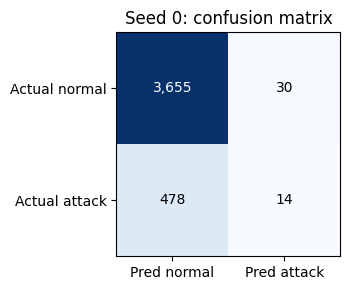

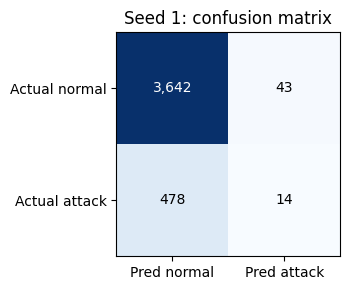

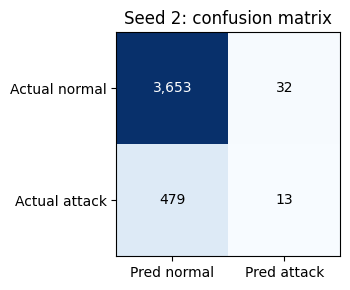

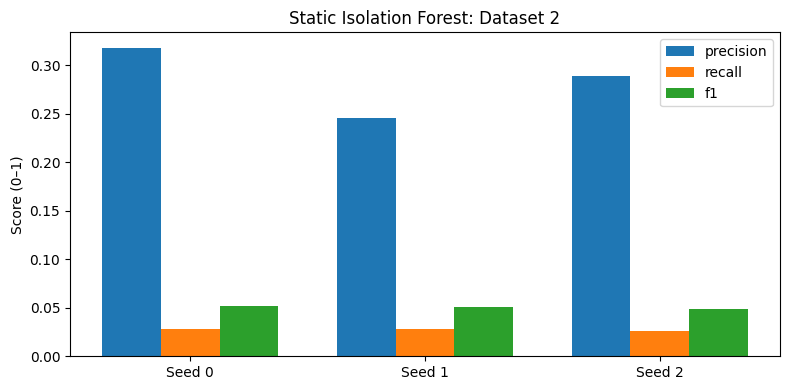

In [13]:
display(summary[['seed','attacks_detected','tp','fp','fn','tn','precision','recall','f1',
                 'roc_auc','pr_auc','mean_delay_hours','false_alarm_episodes_per_week',
                 'clean_hours_under_alarm','calib_in_budget','val_in_budget']].round(4))
display(pd.DataFrame(calibration_results).round(4))
print('Mean ± SD across seeds (exploratory, only 3 seeds):')
metrics_to_summarize=['precision','recall','f1','roc_auc','pr_auc','mean_delay_hours','false_alarm_episodes_per_week']
display(pd.DataFrame({'mean':summary[metrics_to_summarize].mean(),
                      'std':summary[metrics_to_summarize].std(ddof=1)}).round(4))
for seed in SEEDS:
    m=summary.loc[summary.seed==seed].iloc[0]
    fig,ax=plt.subplots(figsize=(3.7,3.0))
    matrix=np.array([[m['tn'],m['fp']],[m['fn'],m['tp']]],dtype=int)
    ax.imshow(matrix,cmap='Blues')
    ax.set_xticks([0,1],['Pred normal','Pred attack']);ax.set_yticks([0,1],['Actual normal','Actual attack'])
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{matrix[i,j]:,}',ha='center',va='center',color=('white' if matrix[i,j]>matrix.max()/2 else 'black'))
    ax.set_title(f'Seed {seed}: confusion matrix')
    fig.tight_layout();fig.savefig(OUTPUT_DIR/f'confusion_seed{seed}.png',dpi=150)
    plt.show()
fig,ax=plt.subplots(figsize=(8,4))
xs=np.arange(len(SEEDS)); width=.25
for i,metric in enumerate(['precision','recall','f1']):
    ax.bar(xs+(i-1)*width,summary[metric].to_numpy(),width,label=metric)
ax.set_xticks(xs,[f'Seed {s}' for s in SEEDS]);ax.set_ylabel('Score (0–1)');ax.set_title('Static Isolation Forest: Dataset 2')
ax.legend();fig.tight_layout();fig.savefig(OUTPUT_DIR/'three_seed_metrics.png',dpi=150);plt.show()


In [14]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    str(OUTPUT_DIR),
    'zip',
    root_dir=OUTPUT_DIR
)

print('Results ZIP:', archive)

files.download(archive)

Results ZIP: /content/iforest_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>